# Network Intrusion Detection using Random Forest (CICIDS2017)

**Final Year Project — Machine Learning based Network Intrusion Detection System (NIDS)**

## Project Goal
The goal of this notebook is to build a **multi-class supervised classifier** that can
look at a network flow (a summarized network connection with statistical features such
as duration, packet size, number of packets, etc.) and decide whether it is:

- **Normal** traffic, or one of three well known attack types:
- **DDoS** (Distributed Denial of Service)
- **PortScan** (Port Scanning)
- **BruteForce** (FTP/SSH password brute forcing)

We use the **CICIDS2017** dataset, which is a widely used, publicly available dataset for
NIDS research created by the Canadian Institute for Cybersecurity (CIC). Each row in the
dataset is a network *flow* described by 78 numerical features (packet lengths, inter
arrival times, flag counts, etc.) that were extracted from real network traffic captures.

## Why Random Forest?
Random Forest is an ensemble of decision trees. It is a good first choice for a network
intrusion detection problem because:

- It handles many numerical features without heavy preprocessing.
- It is naturally able to give a *feature importance* ranking, which helps us understand
  which network characteristics matter most for detecting an attack.
- It is fairly robust to overfitting compared to a single decision tree, since it
  averages the predictions of many trees trained on different random subsets of the data.

This project follows, at a simplified/undergraduate level, the general approach used in
the reference paper:

> M. T. Abdelaziz et al., *"Enhancing Network Threat Detection with Random Forest-Based
> NIDS and Permutation Feature Importance,"* Journal of Network and Systems Management,
> 33:2, 2025.

We do **not** try to reproduce every step of that paper (e.g. repeated stratified k-fold
cross validation, custom prediction functions, or permutation importance with many
repeats). Instead we implement a simplified pipeline that is realistic for an
undergraduate final project: load the data, clean it, balance the classes, train a
Random Forest, and evaluate it with standard classification metrics.

## Files used
This notebook expects the following four CICIDS2017 CSV files to be placed in the
**same folder** as this notebook:

- `Monday-WorkingHours_pcap_ISCX.csv` — only normal (BENIGN) traffic
- `Tuesday-WorkingHours_pcap_ISCX.csv` — normal traffic + FTP-Patator and SSH-Patator
  (brute force) attacks
- `Friday-WorkingHours-Afternoon-PortScan_pcap_ISCX.csv` — normal traffic + PortScan
  attacks
- `Friday-WorkingHours-Afternoon-DDos_pcap_ISCX.csv` — normal traffic + DDoS attacks


## 1. Importing Libraries

We import the standard data-science stack:

- `pandas` / `numpy` for loading and manipulating the tabular data.
- `matplotlib` / `seaborn` for plotting (class distribution, confusion matrix, feature
  importance).
- `scikit-learn` for splitting the data, training the Random Forest model, and computing
  evaluation metrics.


In [1]:
import gc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score,
)

# Make plots a bit nicer / readable
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

RANDOM_STATE = 42  # used everywhere we need reproducible randomness


## 2. Loading the Dataset

The CICIDS2017 dataset is split into several CSV files, one per capture day (and
sometimes per attack scenario). We only need four of them for this project, since they
contain the attack types we are interested in (DDoS, PortScan, Brute Force) plus normal
traffic.

The files are loaded directly by their file name (they must sit in the same folder
as this notebook). We read all four CSV files and print their shape (number of rows, number of columns) to
make sure they loaded correctly. Since the combined dataset has almost 1.5 million rows,
we also downcast the numerical columns from 64-bit floats to 32-bit floats right after
loading, to reduce memory usage (the reference paper does something similar in its
"Data Type Optimization" step).


In [2]:
df_monday = pd.read_csv("Monday-WorkingHours.pcap_ISCX.csv")
df_tuesday = pd.read_csv("Tuesday-WorkingHours.pcap_ISCX.csv")
df_portscan = pd.read_csv("Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv")
df_ddos = pd.read_csv("Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv")

print("Monday   ->", df_monday.shape)
print("Tuesday  ->", df_tuesday.shape)
print("PortScan ->", df_portscan.shape)
print("DDoS     ->", df_ddos.shape)

# combine all four days into a single dataframe
data = pd.concat([df_monday, df_tuesday, df_portscan, df_ddos], ignore_index=True)

data.columns = data.columns.str.strip()

float_cols = data.select_dtypes(include=["float64"]).columns
data[float_cols] = data[float_cols].astype("float32")

# the four individual dataframes are no longer needed, free their memory
del df_monday, df_tuesday, df_portscan, df_ddos
gc.collect()
print("\nCombined dataset shape:", data.shape)


Monday   -> (529918, 79)
Tuesday  -> (445909, 79)
PortScan -> (286467, 79)
DDoS     -> (225745, 79)

Combined dataset shape: (1488039, 79)


## 3. First Look at the Data

Before doing anything else, we take a quick look at the data: the column names, a few
sample rows, and how many flows belong to each original label.


In [3]:
data.head()


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,49188,4,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,49188,1,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,49188,1,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,49188,1,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,49486,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [4]:
data['Label'].value_counts()

Label
BENIGN         1187247
PortScan        158930
DDoS            128027
FTP-Patator       7938
SSH-Patator       5897
Name: count, dtype: int64

## 4. Grouping Labels into 4 Classes

The raw `Label` column contains fine-grained attack names (`FTP-Patator`, `SSH-Patator`,
`DDoS`, `PortScan`, `BENIGN`, ...). For this project we only care about **4 classes**, so
we group the fine-grained labels together:

| Original label(s)            | New class    |
|-------------------------------|--------------|
| `BENIGN`                      | `Normal`     |
| `DDoS`                        | `DDoS`       |
| `PortScan`                    | `PortScan`   |
| `FTP-Patator`, `SSH-Patator`  | `BruteForce` |


In [5]:
label_map = {
    "BENIGN": "Normal",
    "DDoS": "DDoS",
    "PortScan": "PortScan",
    "FTP-Patator": "BruteForce",
    "SSH-Patator": "BruteForce",
}

data["Label"] = data["Label"].map(label_map)

# sanity check: make sure every row got a valid label (no NaN introduced by the mapping)
print("Rows with an unmapped/unknown label:", data["Label"].isna().sum())

data["Label"].value_counts()


Rows with an unmapped/unknown label: 0


Label
Normal        1187247
PortScan       158930
DDoS           128027
BruteForce      13835
Name: count, dtype: int64

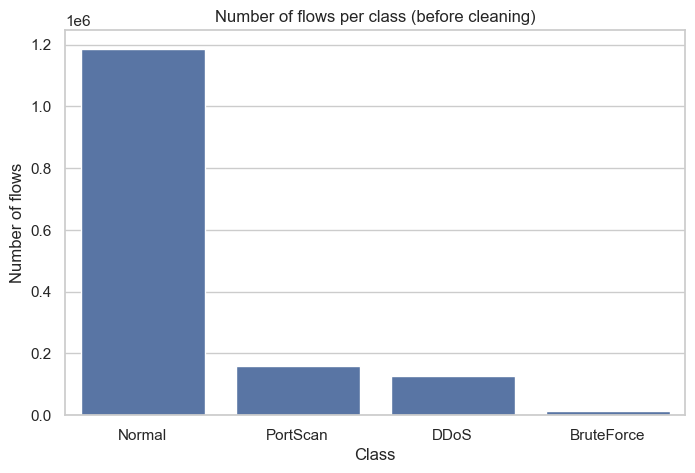

In [6]:
# Visualize the class distribution before any cleaning/balancing
plt.figure()
sns.countplot(x="Label", data=data, order=data["Label"].value_counts().index)
plt.title("Number of flows per class (before cleaning)")
plt.ylabel("Number of flows")
plt.xlabel("Class")
plt.show()

## 5. Data Cleaning

Real-world captured network traffic is never perfectly clean. Before training a model we
need to fix a few common problems in this dataset:

1. **Duplicate rows** — the same flow can appear more than once in the raw CSV files.
2. **Infinite values** — a few numerical features (e.g. `Flow Bytes/s`) can become
   infinite when the flow duration is extremely small (division by a number close to
   zero).
3. **Missing values (NaN)** — some rows have missing feature values.

We remove duplicated rows, replace infinite values with `NaN`, and then drop every row
that contains at least one `NaN` value. Since the dataset is very large (almost 1.5
million rows), removing a relatively small number of problematic rows does not hurt us.


In [7]:
print("Rows before cleaning:", len(data))

# 1) remove exact duplicate rows
before = len(data)
data = data.drop_duplicates()
print("Duplicate rows removed:", before - len(data))

# 2) replace +inf / -inf with NaN in numeric columns
numeric_cols = data.select_dtypes(include=[np.number]).columns
data[numeric_cols] = data[numeric_cols].replace([np.inf, -np.inf], np.nan)

# 3) drop rows with any missing value
before = len(data)
data = data.dropna()
print("Rows with NaN/Inf removed:", before - len(data))

gc.collect()
print("Rows after cleaning:", len(data))


Rows before cleaning: 1488039
Duplicate rows removed: 143882
Rows with NaN/Inf removed: 905
Rows after cleaning: 1343252


## 6. Handling Class Imbalance (Undersampling)

Looking at the class counts, the **Normal** class is much larger than the three attack
classes (this is expected: on a real network, most traffic is legitimate). Training a
classifier directly on this imbalanced data would make the model biased towards
predicting "Normal" all the time.

To keep the problem manageable and reduce the imbalance, we randomly **undersample** the
`Normal` class down to 150,000 flows, while keeping every flow from the three (much
smaller) attack classes. This is a simple form of the undersampling idea used in the
reference paper, without reproducing their full percentage-based balancing procedure.


In [8]:
print(data['Label'].value_counts())

normal_flows = data[data['Label'] == 'Normal']
attack_flows = data[data['Label'] != 'Normal']

normal_sample = normal_flows.sample(n=150_000, random_state=RANDOM_STATE)

data_balanced = pd.concat([normal_sample, attack_flows], ignore_index=True)

# the full (imbalanced) dataset is no longer needed, free its memory
del data, normal_flows, attack_flows, normal_sample
gc.collect()

print("\nBalanced dataset shape:", data_balanced.shape)
data_balanced['Label'].value_counts()


Label
Normal        1115394
DDoS           128014
PortScan        90694
BruteForce       9150
Name: count, dtype: int64

Balanced dataset shape: (377858, 79)


Label
Normal        150000
DDoS          128014
PortScan       90694
BruteForce      9150
Name: count, dtype: int64

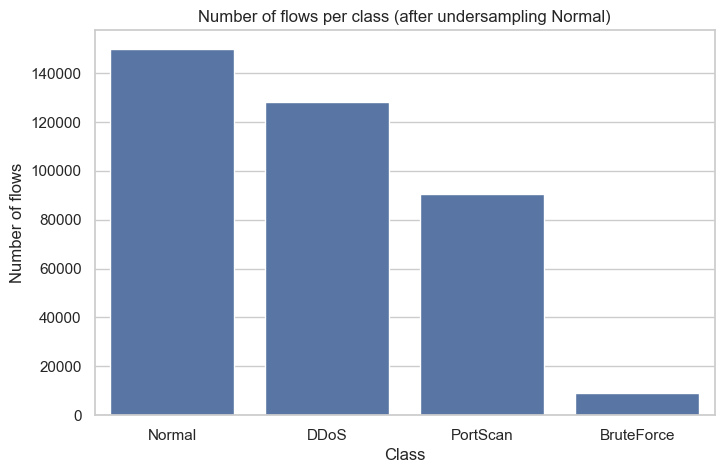

In [9]:
plt.figure()
sns.countplot(x="Label", data=data_balanced,
              order=data_balanced["Label"].value_counts().index)
plt.title("Number of flows per class (after undersampling Normal)")
plt.ylabel("Number of flows")
plt.xlabel("Class")
plt.show()


## 7. Preparing Features (X) and Target (y)

We separate the dataset into:

- `X` — the input features (all the numerical flow statistics).
- `y` — the target label (`Normal`, `DDoS`, `PortScan`, `BruteForce`).

A few columns are identifiers (like `Flow ID`, source/destination IP, `Timestamp`) and
do not represent a general statistical pattern of the traffic — a model trained on IP
addresses could simply "memorize" which IP was attacking during data collection, instead
of learning generalizable attack behaviour. If these columns exist in the dataset, we
drop them before training.


In [10]:
id_like_columns = ['Flow ID', 'Source IP', 'Destination IP', 'Timestamp']
existing_id_columns = [c for c in id_like_columns if c in data_balanced.columns]
print("Identifier columns found and dropped:", existing_id_columns)

data_balanced = data_balanced.drop(columns=existing_id_columns)

X = data_balanced.drop(columns=['Label'])
y = data_balanced['Label']

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of features used:", X.shape[1])


Identifier columns found and dropped: []
X shape: (377858, 78)
y shape: (377858,)
Number of features used: 78


## 8. Train / Test Split

We split the data into a **training set (80%)** and a **test set (20%)**. The model
only ever sees the training set during learning; the test set is kept aside to check how
well the model generalizes to data it has never seen.

We use `stratify=y` so that the proportion of each class is the same in both the
training and the test set — this matters a lot when classes are imbalanced.


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)


Training set size: (302286, 78)
Test set size: (75572, 78)


## 9. Training the Random Forest Classifier

We train a `RandomForestClassifier` with:

- `n_estimators=100` — the forest is made of 100 decision trees.
- `class_weight="balanced"` — even though we already undersampled the Normal class,
  there is still some imbalance between DDoS/PortScan and BruteForce; this option makes
  the model pay relatively more attention to the smaller classes during training.
- `random_state=42` — for reproducible results.


In [12]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,  # use all available CPU cores to speed up training
)

rf_model.fit(X_train, y_train)
print("Model training completed.")


Model training completed.


## 10. Evaluating the Model

We evaluate the trained model on the **test set** (data it has never seen during
training) using standard classification metrics:

- **Precision** — of all flows predicted as a given class, how many actually belong to
  that class.
- **Recall** — of all flows that actually belong to a given class, how many the model
  correctly found.
- **F1-score** — the harmonic mean of precision and recall, a balanced measure of both.
- **Macro F1-score** — the average F1-score across all classes, treating every class
  equally regardless of how many samples it has. This is especially important here
  because it tells us how well the model handles the *rare* attack classes (e.g.
  BruteForce), not just the common ones.
- **Weighted F1-score** — same as macro, but weighted by the number of samples per
  class, giving an overall performance summary.


In [13]:
y_pred = rf_model.predict(X_test)

print(classification_report(y_test, y_pred, digits=4))

macro_f1 = f1_score(y_test, y_pred, average="macro")
weighted_f1 = f1_score(y_test, y_pred, average="weighted")
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy:       {accuracy:.4f}")
print(f"Macro F1-score:    {macro_f1:.4f}")
print(f"Weighted F1-score: {weighted_f1:.4f}")


              precision    recall  f1-score   support

  BruteForce     1.0000    0.9989    0.9995      1830
        DDoS     1.0000    1.0000    1.0000     25603
      Normal     0.9998    1.0000    0.9999     30000
    PortScan     1.0000    0.9998    0.9999     18139

    accuracy                         0.9999     75572
   macro avg     0.9999    0.9997    0.9998     75572
weighted avg     0.9999    0.9999    0.9999     75572

Accuracy:       0.9999
Macro F1-score:    0.9998
Weighted F1-score: 0.9999


### Confusion Matrix

The confusion matrix shows, for every true class (rows), how many flows were predicted
as each class (columns). A perfect classifier would have all its values on the diagonal.


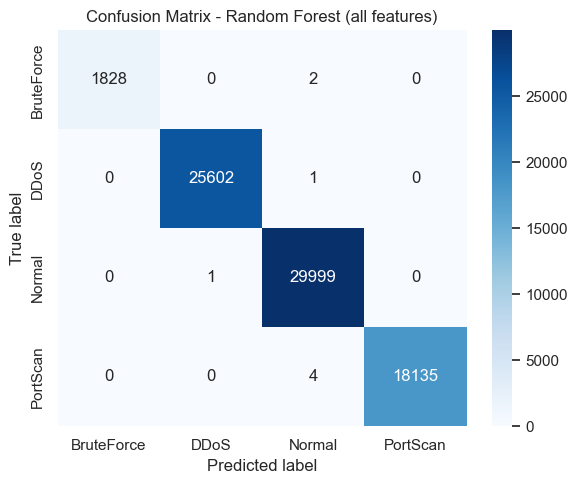

In [14]:
class_labels = rf_model.classes_
cm = confusion_matrix(y_test, y_pred, labels=class_labels)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix - Random Forest (all features)")
plt.tight_layout()
plt.show()


## 10.1 A Closer Look: True Positives, False Positives, True Negatives, False Negatives

The confusion matrix above already contains everything we need, but it is worth slowing
down and looking at it through a different, very common lens in classification problems:
**True Positive (TP)**, **True Negative (TN)**, **False Positive (FP)**, and
**False Negative (FN)**.

These four terms are usually defined for a *binary* (two-class) problem. Since our
problem has four classes, we apply a standard trick called **One-vs-Rest**: for every
class, we temporarily treat that one class as "Positive" and all the other three classes
together as "Negative". We repeat this once for every class, so we end up with four small
2x2 tables instead of one big 4x4 table.

Let's define the four terms using **DDoS** as the example "Positive" class:

- **True Positive (TP)** — the flow is really a DDoS attack, and the model correctly
  predicted DDoS.
- **True Negative (TN)** — the flow is really *not* DDoS (it is Normal, PortScan, or
  BruteForce), and the model correctly predicted "not DDoS".
- **False Positive (FP)** — the flow is really *not* DDoS, but the model incorrectly
  predicted DDoS. This is a **false alarm**.
- **False Negative (FN)** — the flow really *is* DDoS, but the model incorrectly
  predicted something else (e.g. Normal). This is a **missed attack**.

|                        | Actually DDoS | Actually NOT DDoS |
|------------------------|:-------------:|:------------------:|
| **Predicted DDoS**     | TP            | FP                 |
| **Predicted NOT DDoS** | FN            | TN                 |

Once we have TP, FP, FN, and TN for a class, the familiar metrics fall out directly from
them:

- **Precision** = TP / (TP + FP) — of everything the model *called* DDoS, how much really
  was DDoS? A low precision means too many false alarms.
- **Recall** = TP / (TP + FN) — of everything that *really was* DDoS, how much did the
  model catch? A low recall means the model is missing real attacks.
- **Specificity** = TN / (TN + FP) — of everything that was *not* DDoS, how much did the
  model correctly leave alone?

### Why this distinction matters specifically for an intrusion detection system

In network security, a **False Positive** and a **False Negative** do **not** cost the
same thing:

- A **False Positive** (normal traffic flagged as an attack) wastes the time of a security
  analyst and can annoy legitimate users if their traffic gets blocked. Annoying, but
  recoverable.
- A **False Negative** (a real attack flagged as normal traffic) means the attack goes
  through completely undetected. This is the far more dangerous mistake, because the
  whole purpose of the system — catching intrusions — has failed silently.

This is why, for the three attack classes (DDoS, PortScan, BruteForce), we care about
**Recall** at least as much as Precision: a missed attack (FN) is a worse outcome than an
extra false alarm (FP). We compute the exact TP/FP/FN/TN numbers for every class below.


In [15]:
def per_class_confusion_counts(cm, labels):
    """Turn a multi-class confusion matrix into One-vs-Rest TP/FP/FN/TN counts
    and the derived Precision/Recall/Specificity for every class."""
    total = cm.sum()
    rows = []
    for i, label in enumerate(labels):
        TP = cm[i, i]
        FN = cm[i, :].sum() - TP   # rest of the true row, minus the correct cell
        FP = cm[:, i].sum() - TP   # rest of the predicted column, minus the correct cell
        TN = total - TP - FN - FP

        precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
        recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
        specificity = TN / (TN + FP) if (TN + FP) > 0 else 0.0

        rows.append({
            "Class": label,
            "TP": TP, "FP": FP, "FN": FN, "TN": TN,
            "Precision": round(precision, 4),
            "Recall": round(recall, 4),
            "Specificity": round(specificity, 4),
        })
    return pd.DataFrame(rows)

per_class_df = per_class_confusion_counts(cm, class_labels)
per_class_df


,Class,TP,FP,FN,TN,Precision,Recall,Specificity
0,BruteForce,1828,0,2,73742,1.0000,0.9989,1.0000
1,DDoS,25602,1,1,49968,1.0000,1.0000,1.0000
2,Normal,29999,7,1,45565,0.9998,1.0000,0.9998
3,PortScan,18135,0,4,57433,1.0000,0.9998,1.0000


Looking at this table, two things stand out:

- **False Negatives are extremely low for every attack class** (2 for BruteForce, 1 for
  DDoS, 4 for PortScan out of tens of thousands of test samples). In other words, the
  model almost never lets an attack slip through undetected, which is exactly the
  priority we described above.
- **False Positives are also extremely low**, meaning the model rarely raises a false
  alarm on normal traffic either. The only class with a slightly higher FP count is
  Normal itself (7), which corresponds to a handful of attack flows being mistaken for
  normal traffic.

Because both FP and FN are so small across the board, Precision, Recall, and Specificity
all sit above 99.8% for every class, which matches the very high Macro and Weighted
F1-scores reported earlier.


## 12. Feature Importance

One of the useful properties of a Random Forest is that it can tell us which features
were most useful for making decisions. Here we plot the top 15 most important features
according to the model's built-in `feature_importances_` (this is the *Gini importance*,
also called *Mean Decrease in Impurity*).

The reference paper additionally computes *permutation importance*, which is a more
expensive but sometimes more reliable way of ranking features. For this project we keep
things simpler and rely on the Random Forest's built-in importance score, which is
already enough to understand which network characteristics matter the most (for example,
the destination port and packet-length related features tend to be very informative for
telling attacks apart from normal traffic).


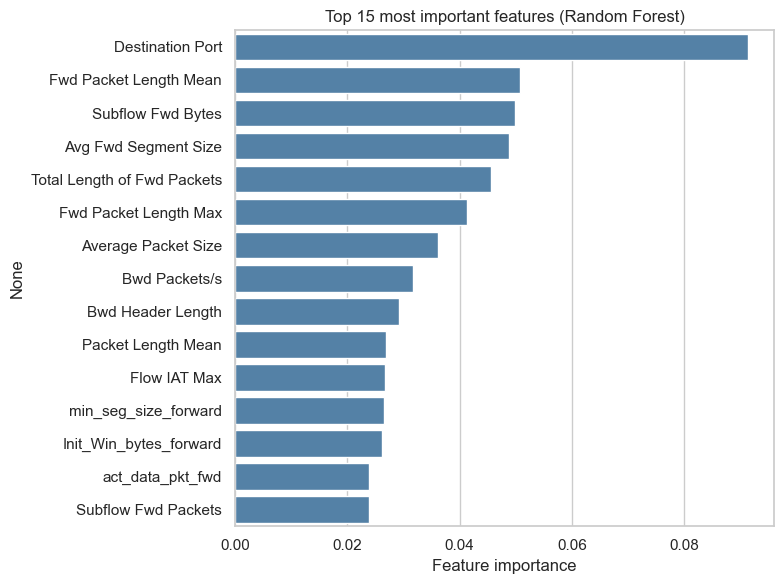

Destination Port               0.091394
Fwd Packet Length Mean         0.050799
Subflow Fwd Bytes              0.049928
Avg Fwd Segment Size           0.048800
Total Length of Fwd Packets    0.045553
Fwd Packet Length Max          0.041213
Average Packet Size            0.036186
Bwd Packets/s                  0.031661
Bwd Header Length              0.029160
Packet Length Mean             0.026868
Flow IAT Max                   0.026713
min_seg_size_forward           0.026543
Init_Win_bytes_forward         0.026159
act_data_pkt_fwd               0.023907
Subflow Fwd Packets            0.023832
dtype: float64

In [16]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
top_features = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=top_features.values, y=top_features.index, color="steelblue")
plt.xlabel("Feature importance")
plt.title("Top 15 most important features (Random Forest)")
plt.tight_layout()
plt.show()

top_features


## 13. A Smaller Model Using Only the Top 20 Features

As a final experiment, we check whether we really need all 78 features, or whether a
much smaller feature set already gives similar performance. We select the top 20
features found in the previous step and retrain a new Random Forest using only these
features.

This is useful in practice: a model with fewer features is faster to run and easier to
deploy in a real-time NIDS, since fewer statistics need to be computed for every flow.


In [17]:
top20_features = importances.sort_values(ascending=False).head(20).index.tolist()
print("Top 20 selected features:")
print(top20_features)

X_top20 = X[top20_features]

X_train20, X_test20, y_train20, y_test20 = train_test_split(
    X_top20, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

rf_model_top20 = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rf_model_top20.fit(X_train20, y_train20)

y_pred20 = rf_model_top20.predict(X_test20)
print(classification_report(y_test20, y_pred20, digits=4))

macro_f1_20 = f1_score(y_test20, y_pred20, average="macro")
weighted_f1_20 = f1_score(y_test20, y_pred20, average="weighted")
print(f"Macro F1-score (20 features):    {macro_f1_20:.4f}")
print(f"Weighted F1-score (20 features): {weighted_f1_20:.4f}")


Top 20 selected features:
['Destination Port', 'Fwd Packet Length Mean', 'Subflow Fwd Bytes', 'Avg Fwd Segment Size', 'Total Length of Fwd Packets', 'Fwd Packet Length Max', 'Average Packet Size', 'Bwd Packets/s', 'Bwd Header Length', 'Packet Length Mean', 'Flow IAT Max', 'min_seg_size_forward', 'Init_Win_bytes_forward', 'act_data_pkt_fwd', 'Subflow Fwd Packets', 'Fwd Header Length', 'Bwd Packet Length Min', 'Fwd Header Length.1', 'Flow Packets/s', 'Subflow Bwd Packets']
              precision    recall  f1-score   support

  BruteForce     1.0000    1.0000    1.0000      1830
        DDoS     0.9999    0.9999    0.9999     25603
      Normal     0.9998    0.9999    0.9999     30000
    PortScan     0.9999    0.9998    0.9999     18139

    accuracy                         0.9999     75572
   macro avg     0.9999    0.9999    0.9999     75572
weighted avg     0.9999    0.9999    0.9999     75572

Macro F1-score (20 features):    0.9999
Weighted F1-score (20 features): 0.9999


In [18]:
print("Comparison of the two models:\n")
print(f"{'Model':<28}{'Macro F1':>12}{'Weighted F1':>15}")
print(f"{'Random Forest (78 features)':<28}{macro_f1:>12.4f}{weighted_f1:>15.4f}")
print(f"{'Random Forest (20 features)':<28}{macro_f1_20:>12.4f}{weighted_f1_20:>15.4f}")


Comparison of the two models:

Model                           Macro F1    Weighted F1
Random Forest (78 features)       0.9998         0.9999
Random Forest (20 features)       0.9999         0.9999


## 14. Conclusion

In this project we built a multi-class Network Intrusion Detection System using the
CICIDS2017 dataset and a Random Forest classifier. After cleaning the data, grouping the
labels into four classes (`Normal`, `DDoS`, `PortScan`, `BruteForce`), and balancing the
classes with simple undersampling, the Random Forest model was able to classify network
flows with a very high macro and weighted F1-score, showing that flow-level statistical
features (packet lengths, timing information, header flags, etc.) contain strong signals
that separate these attack types from normal traffic.

The feature importance analysis showed that a relatively small number of features (such
as the destination port and forward/backward packet length statistics) already carry
most of the information needed for the classification task, and a model trained on only
the top 20 features performs almost as well as the full 78-feature model.

**A note on the very high accuracy.** A Macro F1-score above 99.9% is very high, and it is
worth being upfront about why. Part of the explanation is that DDoS, PortScan, and
BruteForce traffic genuinely have very distinctive flow-level statistics compared to
normal traffic (e.g. destination port patterns, packet timing), so this is a comparatively
"easy" multi-class problem once the classes are this well separated — the same effect is
visible in the reference paper and in most other published work on CICIDS2017. Another
known factor, documented in several studies of this dataset, is that a purely random
train/test split can place near-duplicate flows from the same attack session on both
sides of the split, which can inflate reported accuracy somewhat compared to a
deployment on genuinely unseen traffic. We used a standard random stratified split in
this project for simplicity, so this caveat should be kept in mind when interpreting the
results, and it is listed again as a limitation below.

**Possible future improvements** (not implemented here, left for future work, similar in
spirit to the discussion in the reference paper):

- Using more advanced feature selection techniques such as permutation importance.
- Testing the model on more attack scenarios from the CICIDS2017 dataset (Web Attacks,
  Bot, Infiltration, Heartbleed).
- Comparing Random Forest against other algorithms (e.g. SVM, Gradient Boosting, Neural
  Networks).
- Testing the model in a more realistic, real-time streaming setting instead of a static
  offline dataset.

## Reference

M. T. Abdelaziz, A. Radwan, H. Mamdouh, A. S. Saad, A. S. Abuzaid, A. A. AbdElhakeem,
S. Zakzouk, K. Moussa, M. S. Darweesh, "Enhancing Network Threat Detection with Random
Forest-Based NIDS and Permutation Feature Importance," *Journal of Network and Systems
Management*, vol. 33, no. 2, 2025. https://doi.org/10.1007/s10922-024-09874-0
